In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C2"
DTYPE="LBP"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C2_10,27,"[DATA/TRAINING/C2/C2_10/IMG_6566.HEIC, DATA/TR..."
1,C2_11,25,"[DATA/TRAINING/C2/C2_11/IMG_6666.HEIC, DATA/TR..."
2,C2_12,25,"[DATA/TRAINING/C2/C2_12/IMG_6789.HEIC, DATA/TR..."
3,C2_13,29,"[DATA/TRAINING/C2/C2_13/IMG_6944.HEIC, DATA/TR..."
4,C2_14,25,"[DATA/TRAINING/C2/C2_14/IMG_7189.HEIC, DATA/TR..."
5,C2_15,28,"[DATA/TRAINING/C2/C2_15/IMG_7315.HEIC, DATA/TR..."
6,C2_16,28,"[DATA/TRAINING/C2/C2_16/IMG_7447.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16 %')

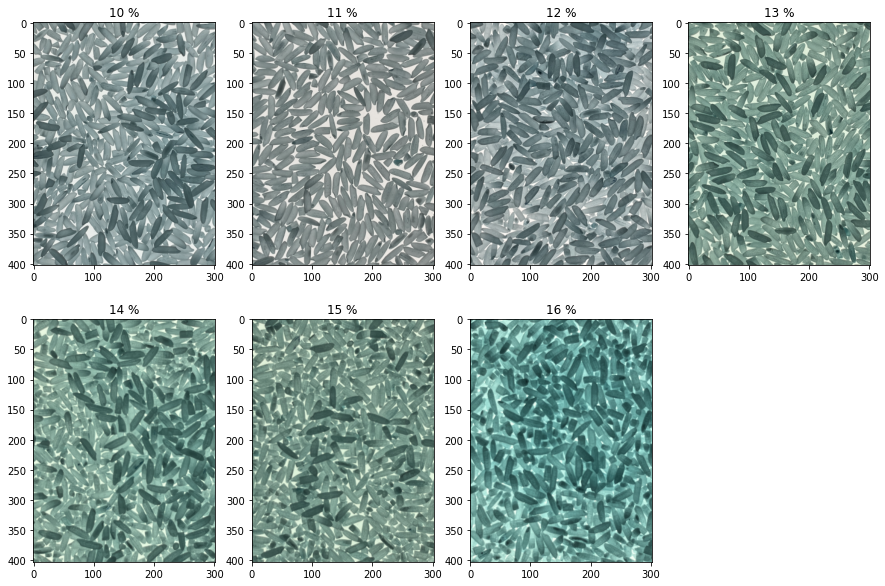

In [6]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1)
image = read_imgHEIC(data_path[0][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10 %")
ax2 = fig.add_subplot(2,4,2)
image = read_imgHEIC(data_path[1][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11 %")
ax3 = fig.add_subplot(2,4,3)
image = read_imgHEIC(data_path[2][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12 %")
ax4 = fig.add_subplot(2,4,4)
image = read_imgHEIC(data_path[3][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13 %")
ax5 = fig.add_subplot(2,4,5)
image = read_imgHEIC(data_path[4][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14 %")
ax6 = fig.add_subplot(2,4,6)
image = read_imgHEIC(data_path[5][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15 %")
ax7 = fig.add_subplot(2,4,7)
image = read_imgHEIC(data_path[6][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16 %")

In [7]:
def fd_gray(gray, bins, mask=None):
    # compute the gray color histogram
    hist  = cv2.calcHist([gray], [0], None, [bins], [0, 256])
    # normalize the histogram
    cv2.normalize(hist, hist)
    # return the histogram
    return hist, hist.flatten()

In [153]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=25
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [154]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.058912,0.044115,0.031348,0.023723,0.020703,0.022984,0.028307,0.048153,0.092742,0.058924,...,0.073481,0.329500,25,16,2,1008,756,3,IMG_6566.HEIC,10
1,0.059739,0.043880,0.030969,0.022825,0.019499,0.021919,0.027498,0.049374,0.095728,0.059685,...,0.074365,0.331095,25,16,2,1008,756,3,IMG_6567.HEIC,10
2,0.058248,0.044111,0.031183,0.022891,0.020248,0.022484,0.028145,0.048021,0.095781,0.059260,...,0.074026,0.330743,25,16,2,1008,756,3,IMG_6568.HEIC,10
3,0.060059,0.044134,0.030862,0.022541,0.019465,0.022266,0.027296,0.048032,0.095645,0.059341,...,0.074865,0.331805,25,16,2,1008,756,3,IMG_6569.HEIC,10
4,0.056823,0.043483,0.030425,0.022975,0.020513,0.023303,0.029372,0.051123,0.100715,0.061861,...,0.071569,0.323829,25,16,2,1008,756,3,IMG_6570.HEIC,10
5,0.056368,0.042887,0.030846,0.023867,0.020804,0.023819,0.029913,0.052220,0.099761,0.062605,...,0.072485,0.318845,25,16,2,1008,756,3,IMG_6571.HEIC,10
6,0.056929,0.042883,0.029951,0.023195,0.019999,0.023350,0.029576,0.052411,0.102167,0.063214,...,0.072070,0.321104,25,16,2,1008,756,3,IMG_6572.HEIC,10
7,0.058486,0.044311,0.031742,0.023489,0.020089,0.022392,0.027943,0.047927,0.096884,0.059449,...,0.074020,0.329033,25,16,2,1008,756,3,IMG_6573.HEIC,10
8,0.059250,0.044287,0.031299,0.022963,0.020455,0.022230,0.027986,0.048074,0.093535,0.058726,...,0.074329,0.333053,25,16,2,1008,756,3,IMG_6574.HEIC,10
9,0.058848,0.044858,0.031326,0.022890,0.019784,0.022118,0.027648,0.047371,0.094645,0.058952,...,0.074728,0.333199,25,16,2,1008,756,3,IMG_6575.HEIC,10


# Classification

In [155]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-8]
#X

In [156]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [157]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [158]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [159]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [160]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,1.000000,1.000000,1.000000,1.000000,LBP,C2,RF_C,25,16,2,1008,756,3
1,2,1.000000,1.000000,1.000000,1.000000,LBP,C2,RF_C,25,16,2,1008,756,3
2,3,0.842105,0.869048,0.857143,0.863054,LBP,C2,RF_C,25,16,2,1008,756,3
3,4,0.789474,0.821429,0.809524,0.815433,LBP,C2,RF_C,25,16,2,1008,756,3
4,5,0.894737,0.892857,0.880952,0.886865,LBP,C2,RF_C,25,16,2,1008,756,3
5,6,0.947368,0.964286,0.952381,0.958296,LBP,C2,RF_C,25,16,2,1008,756,3
6,7,1.000000,1.000000,1.000000,1.000000,LBP,C2,RF_C,25,16,2,1008,756,3
7,8,0.888889,0.916667,0.904762,0.910675,LBP,C2,RF_C,25,16,2,1008,756,3
8,9,1.000000,1.000000,1.000000,1.000000,LBP,C2,RF_C,25,16,2,1008,756,3
9,10,1.000000,1.000000,1.000000,1.000000,LBP,C2,RF_C,25,16,2,1008,756,3


In [161]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C2,RF_C,0.936257,0.940476,0.943432,0.946429


### MLP Classifier

In [162]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [163]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [164]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.947368,0.964286,0.952381,0.958296,LBP,C2,MLP_C,25,16,2,1008,756,3
1,2,0.894737,0.916667,0.904762,0.910675,LBP,C2,MLP_C,25,16,2,1008,756,3
2,3,0.894737,0.916667,0.904762,0.910675,LBP,C2,MLP_C,25,16,2,1008,756,3
3,4,1.000000,1.000000,1.000000,1.000000,LBP,C2,MLP_C,25,16,2,1008,756,3
4,5,0.842105,0.880952,0.833333,0.856481,LBP,C2,MLP_C,25,16,2,1008,756,3
5,6,0.894737,0.916667,0.904762,0.910675,LBP,C2,MLP_C,25,16,2,1008,756,3
6,7,0.842105,0.895238,0.857143,0.875776,LBP,C2,MLP_C,25,16,2,1008,756,3
7,8,0.666667,0.688095,0.690476,0.689284,LBP,C2,MLP_C,25,16,2,1008,756,3
8,9,0.722222,0.690476,0.761905,0.724434,LBP,C2,MLP_C,25,16,2,1008,756,3
9,10,0.944444,0.952381,0.952381,0.952381,LBP,C2,MLP_C,25,16,2,1008,756,3


In [165]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C2,MLP_C,0.864912,0.87619,0.878868,0.882143


### XGBoost Classifier

In [166]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [167]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.947368,0.964286,0.928571,0.946092,LBP,C2,XGB_C,25,16,2,1008,756,3
1,2,0.894737,0.916667,0.880952,0.898455,LBP,C2,XGB_C,25,16,2,1008,756,3
2,3,0.894737,0.942857,0.904762,0.923417,LBP,C2,XGB_C,25,16,2,1008,756,3
3,4,0.842105,0.857143,0.833333,0.845070,LBP,C2,XGB_C,25,16,2,1008,756,3
4,5,0.842105,0.892857,0.857143,0.874636,LBP,C2,XGB_C,25,16,2,1008,756,3
5,6,0.894737,0.916667,0.880952,0.898455,LBP,C2,XGB_C,25,16,2,1008,756,3
6,7,0.947368,0.952381,0.952381,0.952381,LBP,C2,XGB_C,25,16,2,1008,756,3
7,8,0.888889,0.916667,0.880952,0.898455,LBP,C2,XGB_C,25,16,2,1008,756,3
8,9,0.888889,0.916667,0.880952,0.898455,LBP,C2,XGB_C,25,16,2,1008,756,3
9,10,0.944444,0.952381,0.952381,0.952381,LBP,C2,XGB_C,25,16,2,1008,756,3


In [168]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C2,XGB_C,0.898538,0.895238,0.90878,0.922857


# External validation

In [169]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C2_10,5,"[DATA/TEST/C2/C2_10/IMG_6560.HEIC, DATA/TEST/C..."
1,C2_11,5,"[DATA/TEST/C2/C2_11/IMG_6656.HEIC, DATA/TEST/C..."
2,C2_12,5,"[DATA/TEST/C2/C2_12/IMG._6813.HEIC, DATA/TEST/..."
3,C2_13,5,"[DATA/TEST/C2/C2_13/IMG_6918.HEIC, DATA/TEST/C..."
4,C2_14,5,"[DATA/TEST/C2/C2_14/IMG_7179.HEIC, DATA/TEST/C..."
5,C2_15,5,"[DATA/TEST/C2/C2_15/IMG_7305.HEIC, DATA/TEST/C..."
6,C2_16,5,"[DATA/TEST/C2/C2_16/IMG_7437.HEIC, DATA/TEST/C..."


In [170]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [171]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [172]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.057576,0.044165,0.031633,0.023542,0.020770,0.022898,0.028574,0.049771,0.095427,0.059444,...,0.072243,0.329149,25,16,2,1008,756,3,IMG_6560.HEIC,10
1,0.058096,0.044245,0.031436,0.023548,0.020636,0.022577,0.028145,0.048707,0.094793,0.059971,...,0.072446,0.329483,25,16,2,1008,756,3,IMG_6561.HEIC,10
2,0.056399,0.044468,0.032136,0.024417,0.021316,0.023300,0.028580,0.048287,0.094532,0.060025,...,0.072229,0.326508,25,16,2,1008,756,3,IMG_6563.HEIC,10
3,0.055285,0.043602,0.031515,0.024231,0.021272,0.023600,0.029965,0.051384,0.098277,0.062013,...,0.070091,0.322515,25,16,2,1008,756,3,IMG_6564.HEIC,10
4,0.057401,0.043764,0.031300,0.023984,0.020982,0.023130,0.028725,0.048333,0.095396,0.059437,...,0.072326,0.329457,25,16,2,1008,756,3,IMG_6565.HEIC,10
0,0.060453,0.043685,0.032379,0.024105,0.021129,0.022766,0.027948,0.047185,0.092309,0.057532,...,0.074197,0.329053,25,16,2,1008,756,3,IMG_6656.HEIC,11
1,0.061679,0.044736,0.032304,0.023937,0.020184,0.022325,0.027179,0.046455,0.088872,0.057258,...,0.074852,0.332942,25,16,2,1008,756,3,IMG_6658.HEIC,11
2,0.061840,0.044438,0.032905,0.023954,0.020647,0.022451,0.027463,0.046900,0.089885,0.056389,...,0.075869,0.332230,25,16,2,1008,756,3,IMG_6660.HEIC,11
3,0.061727,0.044539,0.031098,0.023239,0.019530,0.021995,0.027010,0.047607,0.095287,0.057613,...,0.075259,0.331579,25,16,2,1008,756,3,IMG_6661.HEIC,11
4,0.060621,0.044345,0.032157,0.024107,0.020581,0.022210,0.027922,0.047889,0.092674,0.057962,...,0.074247,0.330415,25,16,2,1008,756,3,IMG_6664.HEIC,11


In [173]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [174]:
X_test = dtFeaturesTest.values[:, :-8]
#X_test

In [175]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [176]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [177]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       1.00      1.00      1.00         5
     Class 2       1.00      1.00      1.00         5
     Class 3       1.00      1.00      1.00         5
     Class 4       0.83      1.00      0.91         5
     Class 5       1.00      1.00      1.00         5
     Class 6       1.00      0.80      0.89         5

    accuracy                           0.97        35
   macro avg       0.98      0.97      0.97        35
weighted avg       0.98      0.97      0.97        35



## MLP

In [178]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [179]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00         5
     Class 1       0.83      1.00      0.91         5
     Class 2       1.00      1.00      1.00         5
     Class 3       1.00      0.80      0.89         5
     Class 4       1.00      1.00      1.00         5
     Class 5       1.00      0.20      0.33         5
     Class 6       0.56      1.00      0.71         5

    accuracy                           0.86        35
   macro avg       0.91      0.86      0.84        35
weighted avg       0.91      0.86      0.84        35



## XGBC

In [180]:
y_pred = modelXGBC.predict(X_test_scale) 

In [181]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.80      0.89         5
     Class 1       1.00      1.00      1.00         5
     Class 2       0.83      1.00      0.91         5
     Class 3       1.00      1.00      1.00         5
     Class 4       0.83      1.00      0.91         5
     Class 5       0.83      1.00      0.91         5
     Class 6       1.00      0.60      0.75         5

    accuracy                           0.91        35
   macro avg       0.93      0.91      0.91        35
weighted avg       0.93      0.91      0.91        35

